# Evaluation

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 07.07.2025
- Date of Last Modification: 10.07.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

## 1. Setup

In [47]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### 1.1 Load Libraries 

In [49]:
import os

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from datasets import load_from_disk
from sklearn.model_selection import train_test_split

from app.infer import (embed_dataset,
                       harmonize_adata,
                       tokenize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline,
                       get_average_gene_embed)
from nichejepa.evaluation import (compute_neighborhood_composition,
                                  get_adata_cellphonedb_lr_pairs,
                                  get_adata_omnipath_lr_pairs,
                                  knn_classifier,
                                  linear_classifier,
                                  linear_regressor,
                                  plot_roc_curve)

### 1.2 Configure Paths

In [3]:
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
model_timestamp = '11062025_183320_055'
model_folder_path = f'{artifacts_folder_path}/models/{model_timestamp}'

## 2. Analysis

### 2.1 xhs1000-39b_1p (Xenium Human Skin Eczema)

In [279]:
# Dataset variables
dataset_name = 'xhs1000-39b_1p'
cell_type_key = 'annotation_new7'
niche_key = 'NICHE_NAMES'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch11.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch19.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch32.h5ad']

In [324]:
# Model variables
seed = 0
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None

#### 2.1.1 Retrieve Embeddings

In [287]:
# Harmonize and tokenize data and retrieve embeddings
adata_list = []
dataset_list = []
output_embed_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

    # Tokenize AnnData
    dataset = tokenize_adata(
        adata,
        model_folder_path,
        nproc = 4,
        processing_mode = 'parallel')

    # Save tokenized data
    num_shards = 32
    save_dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
    dataset.save_to_disk(
        save_dataset_path,
        num_shards=num_shards)
    dataset_list.append(dataset)

    # Retrieve cell and neighborhood embeddings
    output_embed = embed_dataset(
        dataset=dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        agg_excluded_tokens=agg_excluded_tokens,
        top_k=top_k,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers)
    output_embed_list.append(output_embed)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle
INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055/token_dictionary.pkl.


Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Saving the dataset (32/32 shards): 100%|██████████| 17832/17832 [00:11<00:00, 1601.99 examples/s]


... (8 outputs left out)

Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Saving the dataset (32/32 shards): 100%|██████████| 18439/18439 [00:11<00:00, 1631.05 examples/s]


In [301]:
# Concatenate AnnData objects of all samples/batches
adata = sc.concat(adata_list, axis=0)

# Retrieve cell and neighborhood embeddings for all samples/batches
cell_emb = np.concatenate([output_embed['cell_emb'] for output_embed in output_embed_list], axis=0)
neighborhood_emb = np.concatenate([output_embed['neighborhood_emb'] for output_embed in output_embed_list], axis=0)

# Add embeddings to AnnData object
adata.obsm['cell_emb'] = cell_emb
adata.obsm['neighborhood_emb'] = neighborhood_emb

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### 2.1.2 Train Niche Transfer Classifier

In [446]:
set(adata_list[0].obs[niche_key].unique().tolist() +
    adata_list[1].obs[niche_key].unique().tolist() +
    adata_list[2].obs[niche_key].unique().tolist())

KeyError: 'NICHE_NAMES'

In [ ]:
# Define custom palette
custom_palette = {
    'KC': '#E41A1C',                              # red
    'KC_T2_LC': '#377EB8',                        # blue
    'Basal epidermis/superficial dermis': '#4DAF4A',  # green
    'Interstitial stroma': '#984EA3',             # purple
    'Perivascular depeer': '#FF7F00',             # orange
    'Schwann_KC_HF': '#A65628',                   # brown
    'Perivascular superficial': '#F781BF',        # pink
    'Sweat gland2': '#999999',                    # gray
    'Sweat gland1': '#66C2A5',                    # teal
    'Muscle': '#FFD92F',                          # yellow
    'Sebocyte': '#A6D854',                        # lime
    'Epidermis with T2': '#E78AC3'                # rose
}

In [ ]:
# Visualize ground truth niche labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=niche_key,
    palette=custom_palette,
    spot_size=30)

sc.pl.spatial(
    adata_list[2],
    color=niche_key,
    palette=custom_palette,
    spot_size=30)   

In [ ]:
# Visualize ground truth niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=niche_key,
    palette=custom_palette,
    spot_size=30)   

In [341]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.1.1.1 Linear Classifier

In [342]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm['neighborhood_emb']

In [347]:
# Get train and validation indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
train_val_labels = niche_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_val = niche_labels[val_indices]
niche_labels_test = niche_labels[test_indices]

In [352]:
# Train and evaluate linear niche transfer classifier
# 0.891 accuracy
pred_niche_labels_test, _, _, model = linear_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_val=niche_features_val,
    labels_val=niche_labels_val,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(niche_categories[pred_niche_labels_test])

Using device: cuda
Epoch 1: Train Loss = 217.5594, Val Loss = 0.4738
Epoch 2: Train Loss = 101.7226, Val Loss = 0.3699
Epoch 3: Train Loss = 85.5124, Val Loss = 0.3328
Epoch 4: Train Loss = 78.0343, Val Loss = 0.3124
Epoch 5: Train Loss = 73.6782, Val Loss = 0.2997
Epoch 6: Train Loss = 71.0410, Val Loss = 0.2906
Epoch 7: Train Loss = 69.0421, Val Loss = 0.2835
Epoch 8: Train Loss = 67.1029, Val Loss = 0.2784
Epoch 9: Train Loss = 65.6287, Val Loss = 0.2736
Epoch 10: Train Loss = 64.5817, Val Loss = 0.2697
Epoch 11: Train Loss = 63.6492, Val Loss = 0.2665
Epoch 12: Train Loss = 63.1062, Val Loss = 0.2634
Epoch 13: Train Loss = 62.0703, Val Loss = 0.2618
Epoch 14: Train Loss = 61.6238, Val Loss = 0.2592
Epoch 15: Train Loss = 61.5035, Val Loss = 0.2570
Epoch 16: Train Loss = 60.3527, Val Loss = 0.2548
Epoch 17: Train Loss = 60.0810, Val Loss = 0.2535
Epoch 18: Train Loss = 59.3881, Val Loss = 0.2513
Epoch 19: Train Loss = 59.1015, Val Loss = 0.2503
Epoch 20: Train Loss = 58.7357, Val Lo

In [379]:
# Store predictions
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

/tmp/ipykernel_1364979/718215267.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'NICHE_NAMES_pred' as categorical


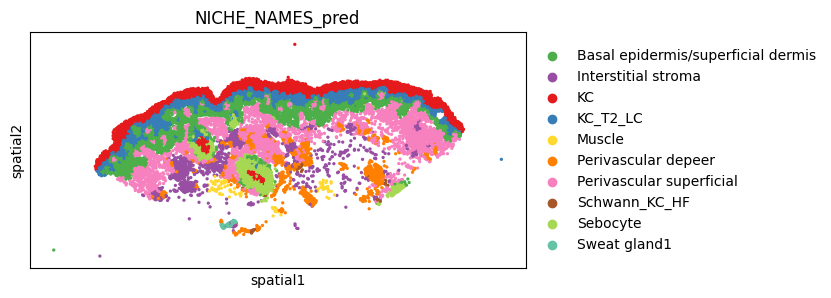

In [380]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=custom_palette,
    spot_size=30)   

##### 2.1.1.2 KNN Classifier

In [383]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [385]:
# Train and evaluate linear niche transfer classifier
# 0.828 accuracy
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test)

Using device: cuda

--- Evaluation Report on Test Set ---
              precision    recall  f1-score   support

           0     0.7999    0.9382    0.8635      3865
           1     0.8802    0.7502    0.8100      1185
           2     0.8443    0.9373    0.8884      2008
           3     0.7587    0.7673    0.7630      2578
           4     0.8947    0.9770    0.9341        87
           5     0.6992    0.7789    0.7369      1298
           6     0.9102    0.9009    0.9055      4421
           7     0.5273    0.5088    0.5179        57
           8     0.8727    0.4668    0.6082      1821
           9     0.9661    0.8906    0.9268        64

    accuracy                         0.8278     17384
   macro avg     0.8153    0.7916    0.7954     17384
weighted avg     0.8327    0.8278    0.8218     17384



In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

/tmp/ipykernel_1364979/2053663697.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'NICHE_NAMES_pred_knn' as categorical


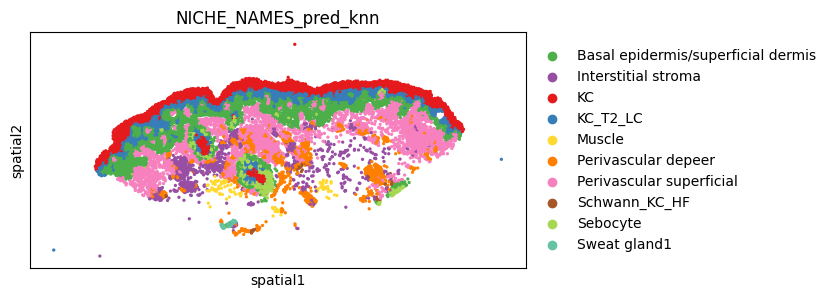

In [386]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=custom_palette,
    spot_size=30)   

#### 2.1.3 Train Cell Type Transfer Classifier

In [396]:
custom_palette = {
    'KC4-5': '#1f78b4',
    'KC3': '#33a02c',
    'KC1': '#fb9a99',
    'Melanocyte': '#e31a1c',
    'KC2': '#a6cee3',
    'F2: Universal': '#fdbf6f',
    'Mac': '#b2df8a',
    'cDC2': '#cab2d6',
    'T': '#6a3d9a',
    'F3: TRC-like': '#ff7f00',
    'F2/3: Bridge': '#b15928',
    'T_GZMK+': '#ffff99',
    'F1: Superficial': '#8dd3c7',
    'VE/Pericyte': '#ffffb3',
    'cDC1': '#bebada',
    'LE': '#fb8072',
    'F5: Schwann-like': '#80b1d3',
    'Sweat gland channel outer': '#fdb462',
    'Sweat gland': '#b3de69',
    'F4: Mixed': '#fccde5',
    'Treg': '#d9d9d9',
    'Nonspecific': '#bc80bd',
    'Pre-adipocyte PPARG+ANGPTL8': '#ccebc5',
    'MigDC': '#ffed6f',
    'LC': '#a1dab4',
    'T_ITGAEhi_IL22': '#41b6c4',
    'T_vascular': '#2c7fb8',
    'Mast cell': '#253494',
    'Muscle': '#fed976',
    'KC_HF_Basal': '#e31a1c',
    'KC_HF_ORS': '#bd0026',
    'Sebocyte_CCL19': '#54278f',
    'Schwann': '#756bb1',
    'Sebocyte_PPARG': '#9e9ac8',
    'ILC2/Tnaive': '#6baed6',
    'F4: TNN+COCH+': '#4292c6',
    'pDC': '#2171b5',
    'KC_HF_inner': '#08519c',
    'LC/MigDC': '#08306b',
    'Plasma cell': '#ff66a1'
}

/tmp/ipykernel_1364979/1255094889.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


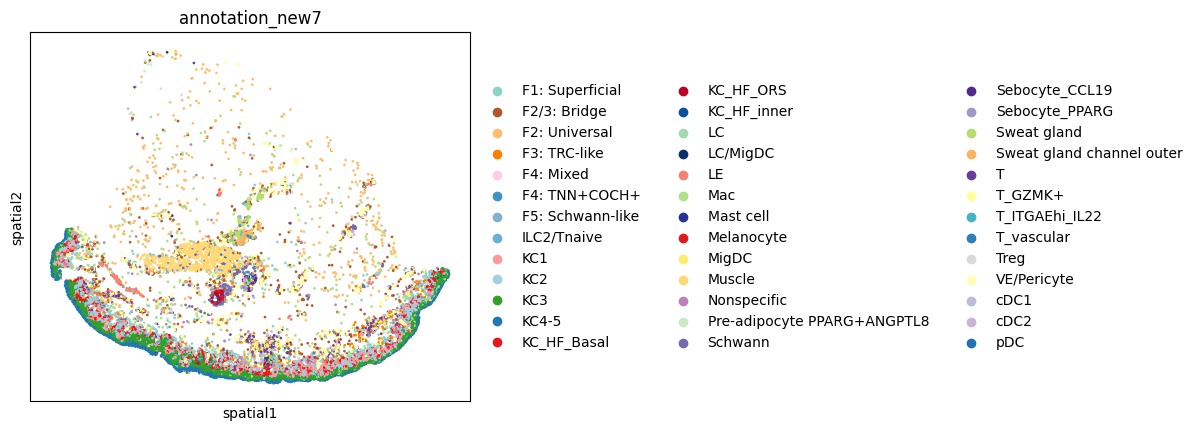

In [393]:
# Visualize ground truth cell type labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=30)   

/tmp/ipykernel_1364979/3804811254.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


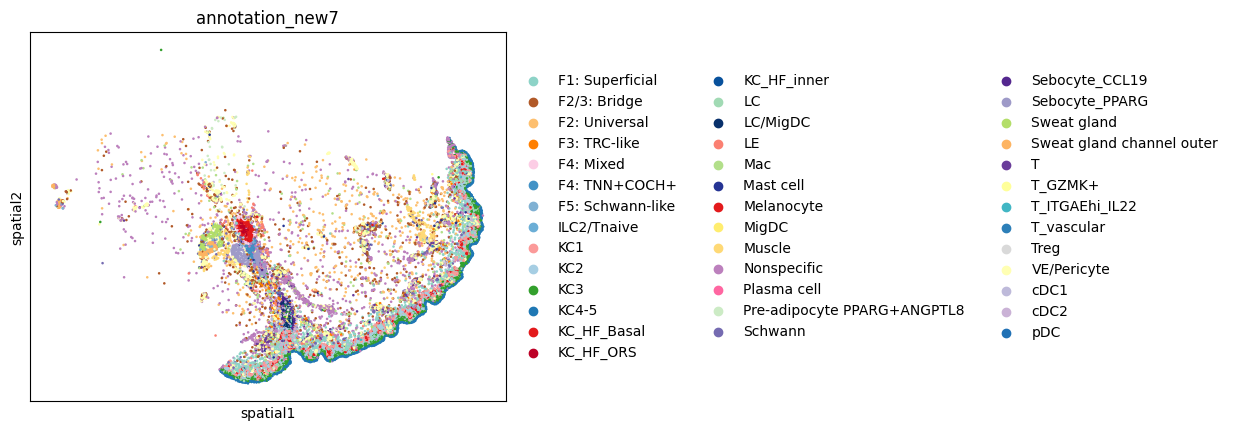

In [397]:
sc.pl.spatial(
    adata_list[2],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=30)   

/tmp/ipykernel_1364979/4070255450.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


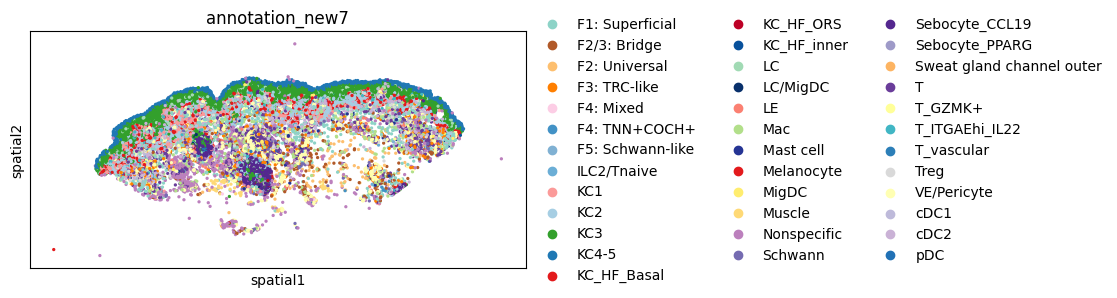

In [398]:
sc.pl.spatial(
    adata_list[1],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=30)   

In [388]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm['cell_emb']

# Get train and validation indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
train_val_labels = cell_type_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_val = cell_type_features[val_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_val = cell_type_labels[val_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [399]:
# Train and evaluate linear niche transfer classifier
# 0.891 accuracy
pred_cell_type_labels_test, _, _, model = linear_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_val=cell_type_features_val,
    labels_val=cell_type_labels_val,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(cell_type_categories[pred_cell_type_labels_test])

Using device: cuda
Epoch 1: Train Loss = 503.7296, Val Loss = 1.3711
Epoch 2: Train Loss = 312.2446, Val Loss = 1.1132
Epoch 3: Train Loss = 270.2238, Val Loss = 1.0029
Epoch 4: Train Loss = 247.8351, Val Loss = 0.9368
Epoch 5: Train Loss = 234.3217, Val Loss = 0.8922
Epoch 6: Train Loss = 225.9358, Val Loss = 0.8597
Epoch 7: Train Loss = 218.6944, Val Loss = 0.8340
Epoch 8: Train Loss = 212.6437, Val Loss = 0.8141
Epoch 9: Train Loss = 206.8041, Val Loss = 0.7978
Epoch 10: Train Loss = 202.0558, Val Loss = 0.7831
Epoch 11: Train Loss = 198.9064, Val Loss = 0.7716
Epoch 12: Train Loss = 196.4221, Val Loss = 0.7612
Epoch 13: Train Loss = 193.2028, Val Loss = 0.7514
Epoch 14: Train Loss = 190.5851, Val Loss = 0.7433
Epoch 15: Train Loss = 188.1884, Val Loss = 0.7362
Epoch 16: Train Loss = 187.8872, Val Loss = 0.7297
Epoch 17: Train Loss = 185.7956, Val Loss = 0.7236
Epoch 18: Train Loss = 183.2658, Val Loss = 0.7182
Epoch 19: Train Loss = 181.7985, Val Loss = 0.7133
Epoch 20: Train Loss 

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metr

In [400]:
adata_test.obs[f'{cell_type_key}_pred'] = cell_type_categories[pred_cell_type_labels_test]

/tmp/ipykernel_1364979/2485538307.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'annotation_new7_pred' as categorical


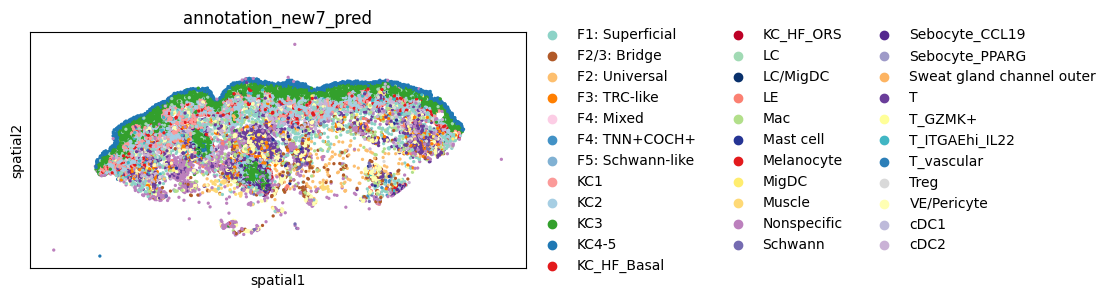

In [401]:
sc.pl.spatial(
    adata_list[1],
    color=f'{cell_type_key}_pred',
    palette=custom_palette,
    spot_size=30)   

Using device: cuda


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capit


--- Evaluation Report on Test Set ---
              precision    recall  f1-score   support

           0     0.6857    0.8455    0.7573       725
           1     0.4685    0.4190    0.4424       284
           2     0.5266    0.7226    0.6092       137
           3     0.6178    0.6699    0.6428       509
           4     1.0000    0.0714    0.1333        14
           5     0.6667    0.2500    0.3636         8
           6     0.0000    0.0000    0.0000         8
           7     0.0000    0.0000    0.0000        75
           8     0.6080    0.7810    0.6837      1388
           9     0.6182    0.7582    0.6811      2039
          10     0.7130    0.8658    0.7820      2608
          11     0.8748    0.8982    0.8864       786
          12     0.0208    0.2500    0.0385         4
          13     0.0357    0.0909    0.0513        11
          14     0.0000    0.0000    0.0000         1
          15     0.4516    0.3439    0.3904       285
          16     0.0213    0.0667    0.032

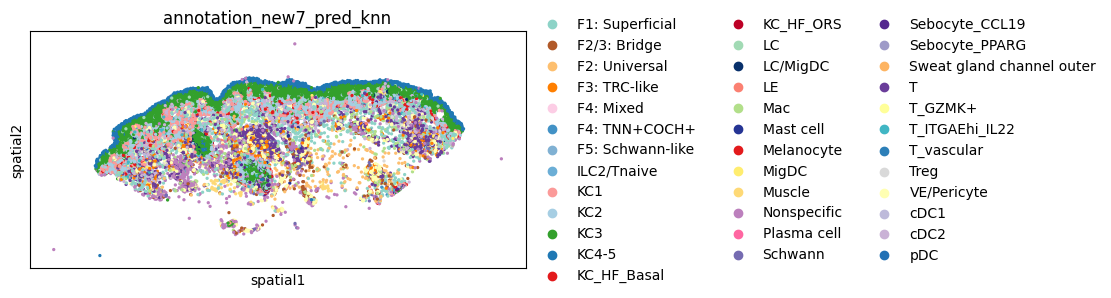

In [402]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test)

adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=custom_palette,
    spot_size=30)   

#### 2.1.4 Train Neighborhood Composition Transfer Classifier

In [411]:
# Get neighborhood composition labels and features
composition_df = compute_neighborhood_composition(adata, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata.obsm['neighborhood_emb']

# Get train and validation indices
train_val_indices = (adata.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
train_val_labels = cell_type_composition_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    #stratify=train_val_labels
)

# Get test indices
test_indices = (adata.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
cell_type_composition_labels_test = cell_type_composition_labels[test_indices]

pred_cell_type_composition_labels, model = linear_regressor(
    features_train=niche_features_train,
    labels_train=cell_type_composition_labels_train,
    features_val=niche_features_val,
    labels_val=cell_type_composition_labels_val,
    features_test=niche_features_test,
    labels_test=cell_type_composition_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(pred_cell_type_composition_labels)

#### 2.1.5 Ligand-Receptor Prediction

In [423]:
lr_database = 'cellphonedb'

In [427]:
adata.var = adata_list[0].var

In [428]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

Downloaded cellphonedb.zip into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded complex_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded gene_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded interaction_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded protein_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded uniprot_synonyms.tsv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources
Downloaded transcription_factor_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources



In [429]:
lr_interaction_df

,ligand,receptor
2,ENSG00000039068,ENSG00000139187
4,ENSG00000170558,ENSG00000104921
232,ENSG00000090339,ENSG00000005844
237,ENSG00000108622,ENSG00000090659
239,ENSG00000076662,ENSG00000090659
...,...,...
2895,ENSG00000170893,ENSG00000174417
2900,ENSG00000204936,ENSG00000261371
2901,ENSG00000196776,ENSG00000198053
2902,ENSG00000196776,ENSG00000089012


In [430]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING AVERAGE GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1441: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
145it [06:42,  2.78s/it]
/nfs/team361/sb75/nichejepa/src/app/infer.py:1704: RuntimeWarning: invalid value encountered in divide
  cell_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))
/nfs/team361/sb75/nichejepa/src/app/infer.py:1711: RuntimeWarning: invalid value encountered in divide
  neighborhood_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))


In [432]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])


(167, 768)
(167, 768)


In [435]:
seed = 0
train_ratio = 0.8
test_ratio = 0.1
val_ratio = 0.1

In [436]:
# --- Splitting using sklearn ---
# First, split off the test set
ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
    ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)

# Then split the remaining temp set into train and val
# The new val ratio is relative to the remaining data
val_relative_ratio = val_ratio / (train_ratio + val_ratio)

ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
    ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)

In [437]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features_train=ligand_receptor_features_train,
    labels_train=ligand_receptor_labels_train,
    features_val=ligand_receptor_features_val,
    labels_val=ligand_receptor_labels_val,
    features_test=ligand_receptor_features_test,
    labels_test=ligand_receptor_labels_test,
    n_epochs=400,
    batch_size=16,
    )

Using device: cuda
Epoch 1: Train Loss = 11.7705, Val Loss = 0.6740
Epoch 2: Train Loss = 11.5102, Val Loss = 0.6713
Epoch 3: Train Loss = 11.2987, Val Loss = 0.6857
Epoch 4: Train Loss = 11.0886, Val Loss = 0.6817
Epoch 5: Train Loss = 10.8564, Val Loss = 0.6634
Epoch 6: Train Loss = 10.6940, Val Loss = 0.6503
Epoch 7: Train Loss = 10.5261, Val Loss = 0.6420
Epoch 8: Train Loss = 10.3534, Val Loss = 0.6483
Epoch 9: Train Loss = 10.2167, Val Loss = 0.6267
Epoch 10: Train Loss = 10.0198, Val Loss = 0.6355
Epoch 11: Train Loss = 9.8759, Val Loss = 0.6298
Epoch 12: Train Loss = 9.7360, Val Loss = 0.6132
Epoch 13: Train Loss = 9.5617, Val Loss = 0.6192
Epoch 14: Train Loss = 9.4324, Val Loss = 0.6125
Epoch 15: Train Loss = 9.3207, Val Loss = 0.5983
Epoch 16: Train Loss = 9.1805, Val Loss = 0.5881
Epoch 17: Train Loss = 9.0399, Val Loss = 0.5831
Epoch 18: Train Loss = 8.9413, Val Loss = 0.5850
Epoch 19: Train Loss = 8.9241, Val Loss = 0.5736
Epoch 20: Train Loss = 8.7403, Val Loss = 0.5703


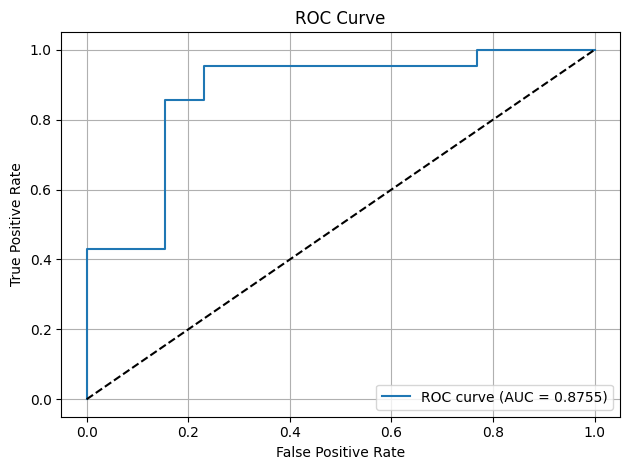

In [438]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from scipy.special import softmax

# Convert to numpy arrays
logits = np.stack(lr_logits)             # shape (N, 2)
labels = np.array(lr_labels)             # shape (N,)

# Apply softmax to get probabilities
probs = softmax(logits, axis=1)       # shape (N, 2)
pos_probs = probs[:, 1]               # probability of class 1

# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(labels, pos_probs)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

### 2.2 chl59-8b_1p (NanoString CosMx Human Lung NSCLC)

In [461]:
# Dataset variables
dataset_name = 'chl59-8b_1p'
cell_type_key = 'cell_type'
niche_key = 'niche'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung12+SMI+Flat+data.tar.h5ad',
    #f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung13+SMI+Flat+data.tar.h5ad', # unannotated
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung5_Rep1+SMI+Flat+data.tar.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung5_Rep2+SMI+Flat+data.tar.h5ad',
    #f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung5_Rep3+SMI+Flat+data.tar.h5ad', # unannotated
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung6+SMI+Flat+data.tar.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung9_Rep1+SMI+Flat+data.tar.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung9_Rep2+SMI+Flat+data.tar.h5ad']
spot_size = 100

In [444]:
# Model variables
seed = 0
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None

#### 2.2.1 Retrieve Embeddings

In [445]:
# Harmonize and tokenize data and retrieve embeddings
adata_list = []
dataset_list = []
output_embed_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

    # Tokenize AnnData
    dataset = tokenize_adata(
        adata,
        model_folder_path,
        nproc = 4,
        processing_mode = 'parallel')

    # Save tokenized data
    num_shards = 32
    save_dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
    dataset.save_to_disk(
        save_dataset_path,
        num_shards=num_shards)
    dataset_list.append(dataset)

    # Retrieve cell and neighborhood embeddings
    output_embed = embed_dataset(
        dataset=dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        agg_excluded_tokens=agg_excluded_tokens,
        top_k=top_k,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers)
    output_embed_list.append(output_embed)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle
INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055/token_dictionary.pkl.


Number of genes with matching ensembl IDs:           946.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Saving the dataset (32/32 shards): 100%|██████████| 72446/72446 [00:38<00:00, 1881.59 examples/s]


... (72 outputs left out)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:997: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  udata=udata,
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
1133it [17:30,  1.08it/s]


In [481]:
adata_list[0].uns['batch']

{'assay': 'cosmx',
 'batch': 'batch0',
 'condition': 'nonsmall_cell_lung_carcinoma',
 'dataset_id': np.int64(59),
 'species': 'homo_sapiens',
 'tissue': 'lung',
 'spatial_neighbors': {'connectivities_key': 'spatial_connectivities',
  'distances_key': 'spatial_distances',
  'params': {'n_neighbors': 10,
   'coord_type': 'generic',
   'radius': None,
   'transform': None}},
 'niche_colors': ['#e41a1cff',
  '#ff7f00ff',
  '#a65628ff',
  '#f781bfff',
  '#999999ff',
  '#66c2a5ff',
  '#ffd92fff',
  '#a6d854ff',
  '#e78ac3ff',
  '#377eb8ff',
  '#4daf4aff',
  '#984ea3ff']}

In [483]:
for i in range(len(adata_list)):
    adata_list[i].obs['batch'] = adata_list[i].uns['batch']

# Concatenate AnnData objects of all samples/batches
adata = sc.concat(adata_list, axis=0)

# Retrieve cell and neighborhood embeddings for all samples/batches
cell_emb = np.concatenate([output_embed['cell_emb'] for output_embed in output_embed_list], axis=0)
neighborhood_emb = np.concatenate([output_embed['neighborhood_emb'] for output_embed in output_embed_list], axis=0)

# Add embeddings to AnnData object
adata.obsm['cell_emb'] = cell_emb
adata.obsm['neighborhood_emb'] = neighborhood_emb

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### 2.2.2 Train Niche Transfer Classifier

In [484]:
# Get unique niche labels
set(adata_list[0].obs[niche_key].unique().tolist() +
    adata_list[1].obs[niche_key].unique().tolist() +
    adata_list[2].obs[niche_key].unique().tolist() +
    adata_list[3].obs[niche_key].unique().tolist() +
    adata_list[4].obs[niche_key].unique().tolist() +
    adata_list[5].obs[niche_key].unique().tolist())

{'1- Tumor (stroma border)',
 '10- Lymphoid rich stroma',
 '11- Lymphoid aggregates',
 '12- Macrophage rich stroma',
 '2- Tumor interior',
 '3- Tumor (neutrophil border)',
 '4- Tumor interior',
 '5- Infiltrated tumor',
 '6- Tumor-infiltrating neutrophils',
 '7- Neutrophil expansion',
 '8- Stroma',
 '9- Plasmablast rich stroma',
 nan}

In [485]:
# Define custom palette
custom_palette = {
    '1- Tumor (stroma border)': '#E41A1C',                              # red
    '10- Lymphoid rich stroma': '#377EB8',                        # blue
    '11- Lymphoid aggregates': '#4DAF4A',  # green
    '12- Macrophage rich stroma': '#984EA3',             # purple
    '2- Tumor interior': '#FF7F00',             # orange
    '3- Tumor (neutrophil border)': '#A65628',                   # brown
    '4- Tumor interior': '#F781BF',        # pink
    '5- Infiltrated tumor': '#999999',                    # gray
    '6- Tumor-infiltrating neutrophils': '#66C2A5',                    # teal
    '7- Neutrophil expansion': '#FFD92F',                          # yellow
    '8- Stroma': '#A6D854',                        # lime
    '9- Plasmablast rich stroma': '#E78AC3'                # rose
}

/tmp/ipykernel_1364979/3464726457.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


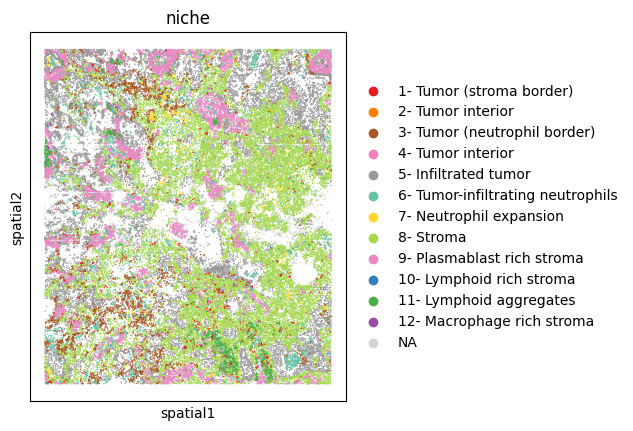

/tmp/ipykernel_1364979/3464726457.py:8: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


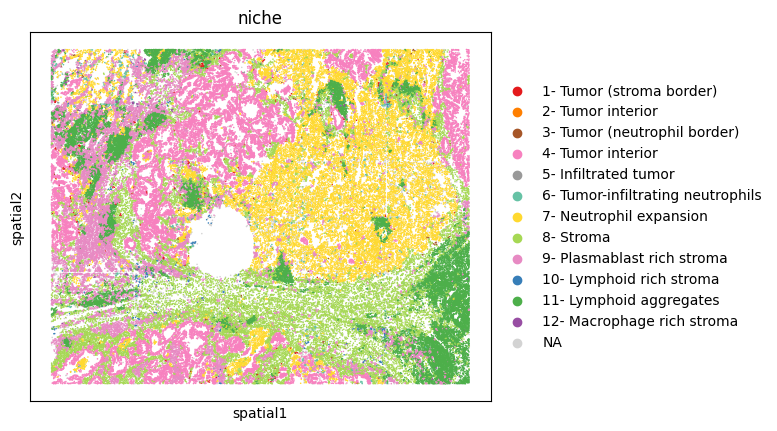

/tmp/ipykernel_1364979/3464726457.py:14: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


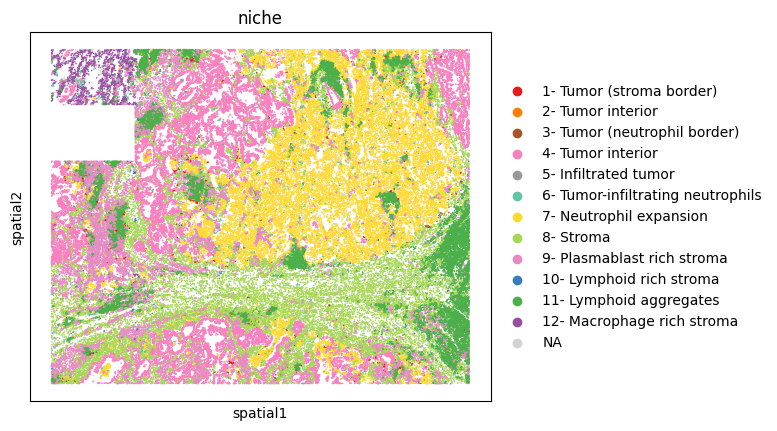

/tmp/ipykernel_1364979/3464726457.py:20: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


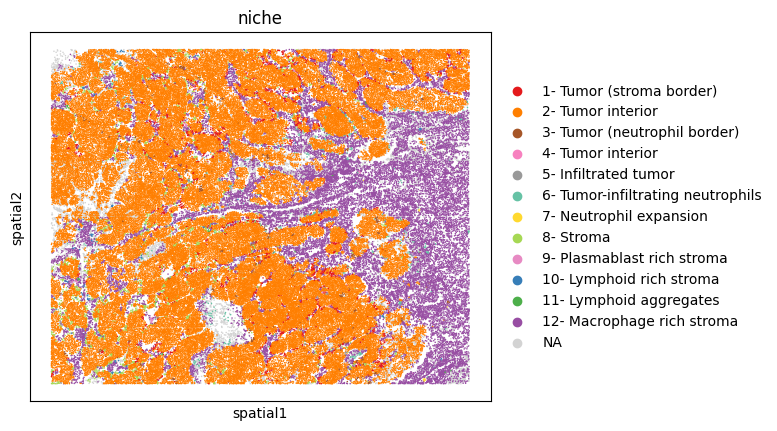

/tmp/ipykernel_1364979/3464726457.py:26: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


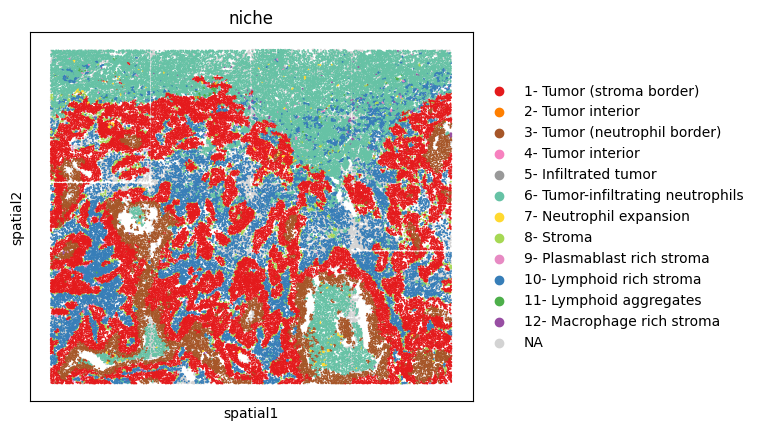

In [463]:
# Visualize ground truth niche labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)

sc.pl.spatial(
    adata_list[1],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)

sc.pl.spatial(
    adata_list[2],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)   

sc.pl.spatial(
    adata_list[3],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)   

sc.pl.spatial(
    adata_list[4],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [486]:
adata_test = adata_list[-1]

/tmp/ipykernel_1364979/1397995119.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


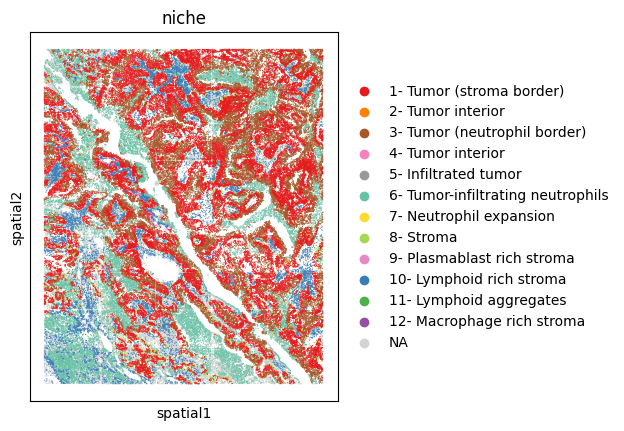

In [470]:
# Visualize ground truth niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [487]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.2.1.1 Linear Classifier

In [488]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm['neighborhood_emb']

In [491]:
# Get train and validation indices
train_val_indices = (adata_filtered.obs['batch'] != 'batch5').to_numpy().nonzero()[0]
train_val_labels = niche_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs['batch'] == 'batch5').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_val = niche_labels[val_indices]
niche_labels_test = niche_labels[test_indices]

In [492]:
# Train and evaluate linear niche transfer classifier
# 0.832 accuracy
pred_niche_labels_test, _, _, model = linear_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_val=niche_features_val,
    labels_val=niche_labels_val,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(niche_categories[pred_niche_labels_test])

Using device: cuda
Epoch 1: Train Loss = 1933.0220, Val Loss = 0.5471
Epoch 2: Train Loss = 1541.7132, Val Loss = 0.5140
Epoch 3: Train Loss = 1476.4016, Val Loss = 0.4978
Epoch 4: Train Loss = 1440.2766, Val Loss = 0.4877
Epoch 5: Train Loss = 1415.1966, Val Loss = 0.4808
Epoch 6: Train Loss = 1396.9923, Val Loss = 0.4746
Epoch 7: Train Loss = 1381.9746, Val Loss = 0.4700
Epoch 8: Train Loss = 1369.2504, Val Loss = 0.4668
Epoch 9: Train Loss = 1358.9686, Val Loss = 0.4628
Epoch 10: Train Loss = 1350.1305, Val Loss = 0.4603
Epoch 11: Train Loss = 1342.0958, Val Loss = 0.4573
Epoch 12: Train Loss = 1334.6522, Val Loss = 0.4551
Epoch 13: Train Loss = 1328.2363, Val Loss = 0.4529
Epoch 14: Train Loss = 1322.1766, Val Loss = 0.4512
Epoch 15: Train Loss = 1317.3690, Val Loss = 0.4493
Epoch 16: Train Loss = 1312.1204, Val Loss = 0.4475
Epoch 17: Train Loss = 1307.7505, Val Loss = 0.4461
Epoch 18: Train Loss = 1303.7160, Val Loss = 0.4449
Epoch 19: Train Loss = 1299.4504, Val Loss = 0.4438
Ep

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metr

In [496]:
adata_test = adata_filtered[adata_filtered.obs['batch'] == 'batch5']

In [497]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

/tmp/ipykernel_1364979/616127455.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]


/tmp/ipykernel_1364979/1345019246.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


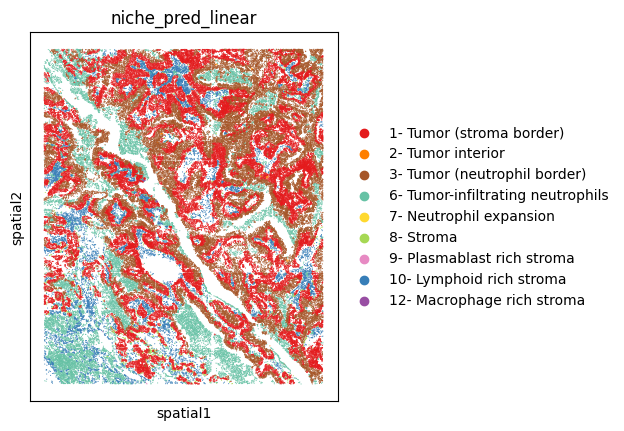

In [499]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=custom_palette,
    spot_size=spot_size)   

##### 2.2.1.2 KNN Classifier

In [500]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['batch'] != 'batch5').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['batch'] == 'batch5').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [504]:
# Train and evaluate linear niche transfer classifier
# 0.789 accuracy
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test)

Using device: cuda

--- Evaluation Report on Test Set ---
              precision    recall  f1-score   support

           0     0.8862    0.7617    0.8192     52076
           1     0.3333    0.0256    0.0476       273
           2     0.6512    0.9644    0.7775     29257
           3     0.0000    0.0000    0.0000         1
           4     0.0000    0.0000    0.0000        63
           5     0.8716    0.7840    0.8255     17628
           6     0.0000    0.0000    0.0000        46
           7     0.3736    0.1044    0.1632      4205
           8     0.0000    0.0000    0.0000       846
           9     0.8731    0.8147    0.8429     11238
          10     0.0000    0.0000    0.0000         8
          11     0.0000    0.0000    0.0000        28

    accuracy                         0.7893    115669
   macro avg     0.3324    0.2879    0.2897    115669
weighted avg     0.7957    0.7893    0.7792    115669



/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metr

In [506]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

/tmp/ipykernel_1364979/428889532.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


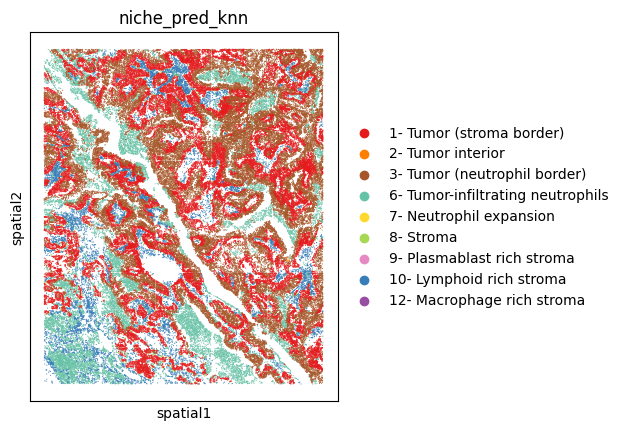

In [508]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=custom_palette,
    spot_size=spot_size)   

#### 2.2.3 Ligand-Receptor Prediction

In [509]:
lr_database = 'cellphonedb'

In [511]:
adata.var = adata_list[0].var

In [513]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

print(lr_interaction_df)

Downloaded cellphonedb.zip into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded complex_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded gene_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded interaction_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded protein_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded uniprot_synonyms.tsv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources
Downloaded transcription_factor_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources

               ligand         receptor
232   ENSG00000090339  ENSG00000005844
237   ENSG00000108622  ENSG00000090659
239   ENSG00000076662  ENSG00000090659
355   ENSG00000142192  ENSG00000019582
359   ENSG00000142192  E

In [514]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING AVERAGE GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1435: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
1133it [38:53,  2.06s/it]


In [515]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])


(87, 768)
(87, 768)


In [516]:
seed = 0
train_ratio = 0.8
test_ratio = 0.1
val_ratio = 0.1

In [517]:
# --- Splitting using sklearn ---
# First, split off the test set
ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
    ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)

# Then split the remaining temp set into train and val
# The new val ratio is relative to the remaining data
val_relative_ratio = val_ratio / (train_ratio + val_ratio)

ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
    ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)

In [518]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features_train=ligand_receptor_features_train,
    labels_train=ligand_receptor_labels_train,
    features_val=ligand_receptor_features_val,
    labels_val=ligand_receptor_labels_val,
    features_test=ligand_receptor_features_test,
    labels_test=ligand_receptor_labels_test,
    n_epochs=400,
    batch_size=16,
    )

Using device: cuda
Epoch 1: Train Loss = 6.2769, Val Loss = 0.6897
Epoch 2: Train Loss = 6.1923, Val Loss = 0.7113
Epoch 3: Train Loss = 6.0835, Val Loss = 0.7138
Epoch 4: Train Loss = 6.0010, Val Loss = 0.7118
Epoch 5: Train Loss = 5.9005, Val Loss = 0.6980
Epoch 6: Train Loss = 5.7898, Val Loss = 0.6883
Epoch 7: Train Loss = 5.7117, Val Loss = 0.6805
Epoch 8: Train Loss = 5.5961, Val Loss = 0.6744
Epoch 9: Train Loss = 5.5529, Val Loss = 0.6770
Epoch 10: Train Loss = 5.4465, Val Loss = 0.6580
Epoch 11: Train Loss = 5.3718, Val Loss = 0.6675
Epoch 12: Train Loss = 5.3047, Val Loss = 0.6440
Epoch 13: Train Loss = 5.1859, Val Loss = 0.6455
Epoch 14: Train Loss = 5.1343, Val Loss = 0.6420
Epoch 15: Train Loss = 5.0336, Val Loss = 0.6356
Epoch 16: Train Loss = 4.9853, Val Loss = 0.6266
Epoch 17: Train Loss = 4.9284, Val Loss = 0.6277
Epoch 18: Train Loss = 4.8535, Val Loss = 0.6160
Epoch 19: Train Loss = 4.7646, Val Loss = 0.6082
Epoch 20: Train Loss = 4.7155, Val Loss = 0.6111
Epoch 21: 

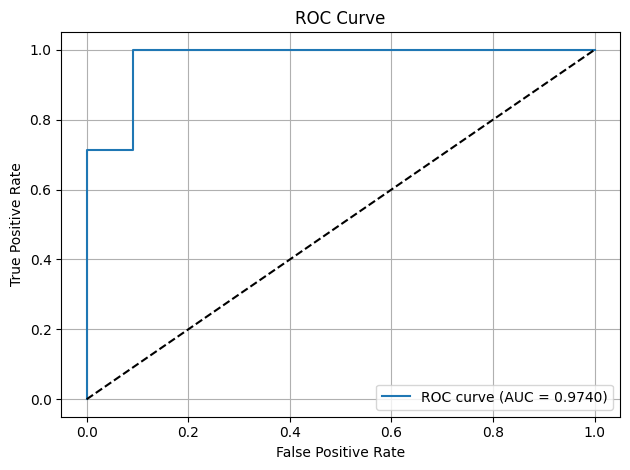

In [519]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from scipy.special import softmax

# Convert to numpy arrays
logits = np.stack(lr_logits)             # shape (N, 2)
labels = np.array(lr_labels)             # shape (N,)

# Apply softmax to get probabilities
probs = softmax(logits, axis=1)       # shape (N, 2)
pos_probs = probs[:, 1]               # probability of class 1

# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(labels, pos_probs)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

### 2.3 xhk1007-41b_1p (Xenium Human Kidney RCC)

In [28]:
# Dataset variables
dataset_name = 'xhk1007-CV1-41b_1p'
cell_type_key = 'level_1_cell_type'
sample_key = 'batch'
test_sample = 'batch14'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-3.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-1.h5ad']
spot_size = 30

In [5]:
# Model variables
seed = 0
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None

train_ratio = 0.8
test_ratio = 0.1
val_ratio = 0.1

#### 2.3.1 Retrieve Embeddings

In [6]:
# Harmonize and tokenize data and retrieve embeddings
adata_list = []
dataset_list = []
output_embed_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

    # Tokenize AnnData
    dataset = tokenize_adata(
        adata,
        model_folder_path,
        nproc = 4,
        processing_mode = 'parallel')

    # Save tokenized data
    num_shards = 32
    save_dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
    dataset.save_to_disk(
        save_dataset_path,
        num_shards=num_shards)
    dataset_list.append(dataset)

    # Retrieve cell and neighborhood embeddings
    output_embed = embed_dataset(
        dataset=dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        agg_excluded_tokens=agg_excluded_tokens,
        top_k=top_k,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers)
    output_embed_list.append(output_embed)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4949.
Number of genes skipped:           0.


INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055/token_dictionary.pkl.


STEP 2: ADDING SPECIAL VALUES...
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


... (14 outputs left out)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:991: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
457it [06:44,  1.13it/s]


In [7]:
for i in range(len(adata_list)):
    adata_list[i].obs['batch'] = adata_list[i].uns['batch']

# Concatenate AnnData objects of all samples/batches
adata = sc.concat(adata_list, axis=0)

# Retrieve cell and neighborhood embeddings for all samples/batches
cell_emb = np.concatenate([output_embed['cell_emb'] for output_embed in output_embed_list], axis=0)
neighborhood_emb = np.concatenate([output_embed['neighborhood_emb'] for output_embed in output_embed_list], axis=0)

# Add embeddings to AnnData object
adata.obsm['cell_emb'] = cell_emb
adata.obsm['neighborhood_emb'] = neighborhood_emb

# Add combined neighborhood graph
blocks = [a.obsp['spatial_connectivities'] for a in adata_list]
combined_graph = sp.block_diag(blocks)
adata.obsp['spatial_connectivities'] = combined_graph

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### 2.3.2 Train Cell Type Transfer Classifier

In [9]:
# Get unique niche labels
set(adata_list[0].obs[cell_type_key].unique().tolist() +
    adata_list[1].obs[cell_type_key].unique().tolist())

{'Endothelium', 'Epithelium', 'Lymphoid', 'Myeloid', 'Stroma'}

In [10]:
custom_palette = {
    'Endothelium': '#1f78b4',
    'Epithelium': '#33a02c',
    'Lymphoid': '#fb9a99',
    'Myeloid': '#e31a1c',
    'Stroma': '#a6cee3'
}

/tmp/ipykernel_1793686/1496452390.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


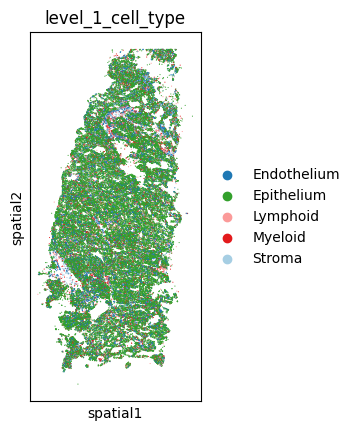

In [13]:
# Visualize ground truth cell type labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=spot_size)   

/tmp/ipykernel_1793686/3429394219.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


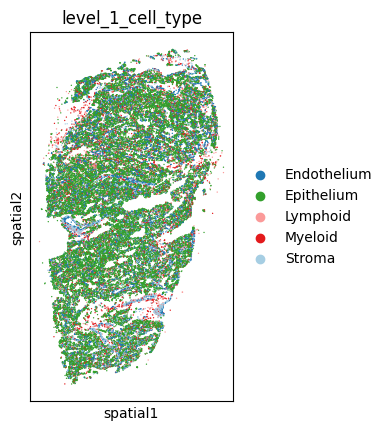

In [15]:
# Visualize ground truth cell type labels in test sample
sc.pl.spatial(
    adata_list[1],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [26]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm['cell_emb']

# Get train and validation indices
train_val_indices = (adata_filtered.obs[sample_key] != test_sample).to_numpy().nonzero()[0]
train_val_labels = cell_type_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs[sample_key] == test_sample).to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_val = cell_type_features[val_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_val = cell_type_labels[val_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [27]:
# Train and evaluate linear niche transfer classifier
# 0.891 accuracy
pred_cell_type_labels_test, _, _, model = linear_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_val=cell_type_features_val,
    labels_val=cell_type_labels_val,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(cell_type_categories[pred_cell_type_labels_test])

Using device: cuda
Epoch 1: Train Loss = 113.5395, Val Loss = 0.1175
Epoch 2: Train Loss = 62.0356, Val Loss = 0.1023
Epoch 3: Train Loss = 56.4249, Val Loss = 0.0965
Epoch 4: Train Loss = 53.6919, Val Loss = 0.0933
Epoch 5: Train Loss = 51.9605, Val Loss = 0.0914
Epoch 6: Train Loss = 50.7521, Val Loss = 0.0896
Epoch 7: Train Loss = 49.8180, Val Loss = 0.0883
Epoch 8: Train Loss = 49.1170, Val Loss = 0.0873
Epoch 9: Train Loss = 48.4484, Val Loss = 0.0866
Epoch 10: Train Loss = 47.9407, Val Loss = 0.0858
Epoch 11: Train Loss = 47.4678, Val Loss = 0.0851


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x150f7789d690>>
Traceback (most recent call last):
  File "/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
KeyboardInterrupt: 


KeyboardInterrupt: 

In [23]:
adata_test = adata_list[1]

In [24]:
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

/tmp/ipykernel_1793686/280232035.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'level_1_cell_type_pred_linear' as categorical


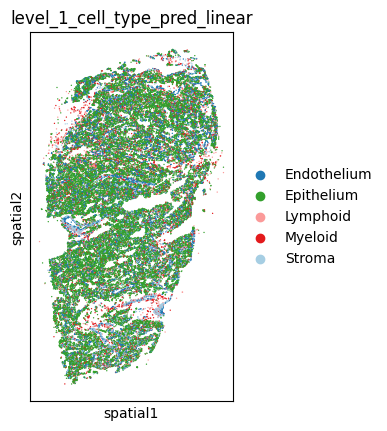

In [25]:
# Visualize predicted labels
sc.pl.spatial(
    adata_list[1],
    color=f'{cell_type_key}_pred_linear',
    palette=custom_palette,
    spot_size=spot_size)   

Using device: cuda

--- Evaluation Report on Test Set ---
              precision    recall  f1-score   support

           0     0.9191    0.9730    0.9453      9928
           1     0.9789    0.9808    0.9798     32210
           2     0.9045    0.9455    0.9246      4388
           3     0.9497    0.9193    0.9343      5232
           4     0.9740    0.8750    0.9219      6674

    accuracy                         0.9593     58432
   macro avg     0.9452    0.9387    0.9412     58432
weighted avg     0.9600    0.9593    0.9591     58432



/tmp/ipykernel_1793686/2066023995.py:20: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'level_1_cell_type_pred_knn' as categorical


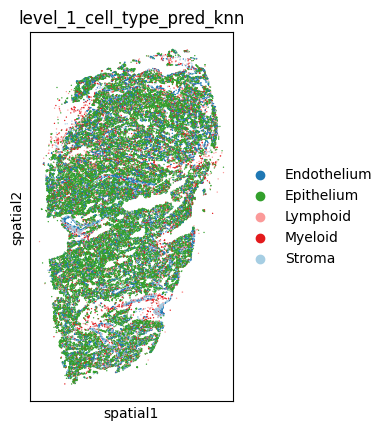

In [29]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != test_sample).to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == test_sample).to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test)

adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=custom_palette,
    spot_size=30)   

#### 2.3.3 Train Neighborhood Composition Transfer Classifier

In [34]:
# Get neighborhood composition labels and features
composition_df = compute_neighborhood_composition(adata, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata.obsm['neighborhood_emb']

# Get train and validation indices
train_val_indices = (adata.obs[sample_key] != test_sample).to_numpy().nonzero()[0]
train_val_labels = cell_type_composition_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    #stratify=train_val_labels
)

# Get test indices
test_indices = (adata.obs[sample_key] == test_sample).to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
cell_type_composition_labels_test = cell_type_composition_labels[test_indices]

pred_cell_type_composition_labels, model = linear_regressor(
    features_train=niche_features_train,
    labels_train=cell_type_composition_labels_train,
    features_val=niche_features_val,
    labels_val=cell_type_composition_labels_val,
    features_test=niche_features_test,
    labels_test=cell_type_composition_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(pred_cell_type_composition_labels)

Using device: cuda
Epoch 1: Train Loss = 5.4852, Val Loss = 0.0056
Epoch 2: Train Loss = 2.8093, Val Loss = 0.0049
Epoch 3: Train Loss = 2.5628, Val Loss = 0.0046
Epoch 4: Train Loss = 2.4306, Val Loss = 0.0044
Epoch 5: Train Loss = 2.3446, Val Loss = 0.0043
Epoch 6: Train Loss = 2.2836, Val Loss = 0.0042
Epoch 7: Train Loss = 2.2364, Val Loss = 0.0041
Epoch 8: Train Loss = 2.1992, Val Loss = 0.0041
Epoch 9: Train Loss = 2.1680, Val Loss = 0.0040
Epoch 10: Train Loss = 2.1414, Val Loss = 0.0040
Epoch 11: Train Loss = 2.1190, Val Loss = 0.0039
Epoch 12: Train Loss = 2.0989, Val Loss = 0.0039
Epoch 13: Train Loss = 2.0815, Val Loss = 0.0038
Epoch 14: Train Loss = 2.0652, Val Loss = 0.0038
Epoch 15: Train Loss = 2.0501, Val Loss = 0.0038
Epoch 16: Train Loss = 2.0364, Val Loss = 0.0038
Epoch 17: Train Loss = 2.0242, Val Loss = 0.0037
Epoch 18: Train Loss = 2.0131, Val Loss = 0.0037
Epoch 19: Train Loss = 2.0025, Val Loss = 0.0037
Epoch 20: Train Loss = 1.9930, Val Loss = 0.0037
Epoch 21: 

#### 2.3.4 Ligand-Receptor Prediction

In [35]:
lr_database = 'cellphonedb'

In [36]:
adata.var = adata_list[0].var

In [37]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

Downloaded cellphonedb.zip into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded complex_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded gene_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded interaction_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded protein_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded uniprot_synonyms.tsv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources
Downloaded transcription_factor_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources



In [38]:
lr_interaction_df

,ligand,receptor
2,ENSG00000039068,ENSG00000139187
4,ENSG00000170558,ENSG00000104921
232,ENSG00000090339,ENSG00000005844
237,ENSG00000108622,ENSG00000090659
239,ENSG00000076662,ENSG00000090659
...,...,...
2895,ENSG00000170893,ENSG00000174417
2900,ENSG00000204936,ENSG00000261371
2901,ENSG00000196776,ENSG00000198053
2902,ENSG00000196776,ENSG00000089012


In [39]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING AVERAGE GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1435: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
457it [18:54,  2.48s/it]
/nfs/team361/sb75/nichejepa/src/app/infer.py:1692: RuntimeWarning: invalid value encountered in divide
  cell_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))
/nfs/team361/sb75/nichejepa/src/app/infer.py:1699: RuntimeWarning: invalid value encountered in divide
  neighborhood_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))


In [40]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])


(149, 768)
(149, 768)


In [43]:
# --- Splitting using sklearn ---
# First, split off the test set
ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
    ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)

# Then split the remaining temp set into train and val
# The new val ratio is relative to the remaining data
val_relative_ratio = val_ratio / (train_ratio + val_ratio)

ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
    ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)

In [44]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features_train=ligand_receptor_features_train,
    labels_train=ligand_receptor_labels_train,
    features_val=ligand_receptor_features_val,
    labels_val=ligand_receptor_labels_val,
    features_test=ligand_receptor_features_test,
    labels_test=ligand_receptor_labels_test,
    n_epochs=400,
    batch_size=16,
    )

Using device: cuda
Epoch 1: Train Loss = 10.6333, Val Loss = 0.7073
Epoch 2: Train Loss = 10.4663, Val Loss = 0.6928
Epoch 3: Train Loss = 10.2928, Val Loss = 0.6804
Epoch 4: Train Loss = 10.1374, Val Loss = 0.6714
Epoch 5: Train Loss = 9.9806, Val Loss = 0.6610
Epoch 6: Train Loss = 9.8524, Val Loss = 0.6497
Epoch 7: Train Loss = 9.7024, Val Loss = 0.6419
Epoch 8: Train Loss = 9.5645, Val Loss = 0.6347
Epoch 9: Train Loss = 9.4446, Val Loss = 0.6290
Epoch 10: Train Loss = 9.3525, Val Loss = 0.6217
Epoch 11: Train Loss = 9.2231, Val Loss = 0.6173
Epoch 12: Train Loss = 9.1079, Val Loss = 0.6130
Epoch 13: Train Loss = 9.0035, Val Loss = 0.6083
Epoch 14: Train Loss = 8.9146, Val Loss = 0.6032
Epoch 15: Train Loss = 8.8465, Val Loss = 0.6007
Epoch 16: Train Loss = 8.7151, Val Loss = 0.5970
Epoch 17: Train Loss = 8.6796, Val Loss = 0.5916
Epoch 18: Train Loss = 8.5488, Val Loss = 0.5913
Epoch 19: Train Loss = 8.4719, Val Loss = 0.5855
Epoch 20: Train Loss = 8.3892, Val Loss = 0.5829
Epoch 

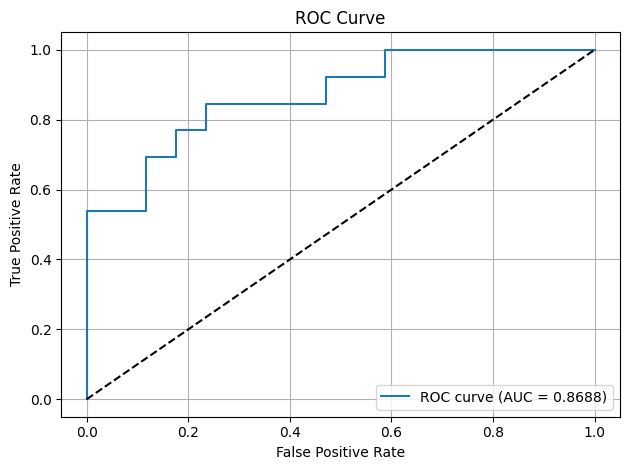

In [50]:
plot_roc_curve(logits=lr_logits, labels=lr_labels)

In [7]:
# Load tokenized data
load_dataset_path = f'{artifacts_folder_path}/{dataset_name}/{dataset_name}.dataset'
dataset = load_from_disk(load_dataset_path)